In [1]:
import numpy as np
import tensorflow as tf
from sionna.rt import load_scene, Transmitter, Receiver, PlanarArray, Camera

import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'numpy'

In [2]:
scene = load_scene("Map2/chalmers_map_v16_extra.xml")

In [3]:
for i, obj in enumerate(scene.objects.values()):
    print(f"{obj.name}: {obj.radio_material.name}")
    if i >= 10:
        break

A-dammen: itu_wet_ground
Arkitektur-__Bygg-_och_Milj_teknik-itu_brick: itu_brick
Arkitektur-__Bygg-_och_Milj_teknik-itu_metal: itu_metal
Arkitektur-__Bygg-_och_Milj_teknik_001-itu_brick: itu_brick
Arkitektur-__Bygg-_och_Milj_teknik_001-itu_metal: itu_metal
CA-Huset_001-itu_brick: itu_brick
CA-Huset_001-itu_metal: itu_metal
CA-Huset_004-itu_brick: itu_brick
CA-Huset_004-itu_metal: itu_metal
CA-Huset_005-itu_brick: itu_brick
CA-Huset_005-itu_metal: itu_metal


In [4]:
scene.tx_array = PlanarArray(num_rows=4, num_cols=4, vertical_spacing=0.5,horizontal_spacing=0.5, pattern="tr38901",polarization="V")

scene.rx_array = PlanarArray(num_rows=1, num_cols=1, vertical_spacing=0.5,horizontal_spacing=0.5, pattern="iso",polarization="V")

# tx = Transmitter("tx", [-197, -6, 16], [0.0, 0.0, 0.0])
#scene.add(tx)    #toy example coordinates

tx2 = Transmitter("tx2", [0.5, -343, 30], [0.0, 0.0, 0.0])   #Chalmers coordinates
scene.add(tx2)

tx3 = Transmitter("tx3", [65, -181.5, 35], [0.0, 0.0, 0.0])  #Chalmers coordinates
scene.add(tx3)

tx4 = Transmitter("tx4", [22, 182, 28], [0.0, 0.0, 0.0])  #Chalmers coordinates
scene.add(tx4)

tx5 = Transmitter("tx5", [-147, 327, 28], [0.0, 0.0, 0.0])  #Chalmers coordinates
scene.add(tx5)

tx6 = Transmitter("tx6", [-212, -33, 15], [0.0, 0.0, 0.0])  #Chalmers coordinates
scene.add(tx6)

#rx = Receiver("rx", [16, -10, 1.5], [0.0, 0.0, 0.0])
#scene.add(rx)   #toy example coordinates

#rx2 = Receiver("rx2", [-46, 28.5, 1.4], [0.0, 0.0, 0.0])
#scene.add(rx2)  #toy example coordinates

#rx3 = Receiver("rx3", [-74, 67, 1.6], [0.0, 0.0, 0.0])
#scene.add(rx3)  #toy example coordinates

#rx4 = Receiver("rx4", [1.3, 9, 1.4], [0.0, 0.0, 0.0])
#scene.add(rx4)  #toy example coordinates

#rx5 = Receiver("rx5", [70, -29, 1.6], [0.0, 0.0, 0.0])
#scene.add(rx5)  #toy example coordinates

#rx6 = Receiver("rx6", [-7.6, 28.5, 1.4], [0.0, 0.0, 0.0])
#scene.add(rx6)  #toy example coordinates

rx7 = Receiver("rx7", [-40, -428, 1.3], [0.0, 0.0, 0.0])  #Chalmers coordinates
scene.add(rx7)

rx8 = Receiver("rx8", [60, -294, 1.6], [0.0, 0.0, 0.0])  #Chalmers coordinates
scene.add(rx8)

#rx9 = Receiver("rx9", [89, -169, 1.5], [0.0, 0.0, 0.0])  #Chalmers coordinates
#scene.add(rx9)

#rx10 = Receiver("rx10", [55.6, -26, 1.6], [0.0, 0.0, 0.0])  #Chalmers coordinates
#scene.add(rx10)

#rx11 = Receiver("rx11", [-35, 106, 1.5], [0.0, 0.0, 0.0])  #Chalmers coordinates
#scene.add(rx11)

#rx12 = Receiver("rx12", [-70, 0.3, 1.6], [0.0, 0.0, 0.0])  #Chalmers coordinates
#scene.add(rx12)

#rx13 = Receiver("rx13", [-116, 229, 1.5], [0.0, 0.0, 0.0])  #Chalmers coordinates
#scene.add(rx13)

#rx14 = Receiver("rx14", [-253, 402, 1.5], [0.0, 0.0, 0.0])  #Chalmers coordinates
#scene.add(rx14)

#rx15 = Receiver("rx15", [-235, 25, 1.6], [0.0, 0.0, 0.0])  #Chalmers coordinates
#scene.add(rx15)

#rx16 = Receiver("rx16", [-248, -52, 1.6], [0.0, 0.0, 0.0])  #Chalmers coordinates
#scene.add(rx16)


In [5]:
cm = scene.coverage_map(cm_cell_size=[1,1], num_samples=10e6, diffraction=True, scattering=True)
paths = scene.compute_paths(max_depth=10)

#Create new camera with different configuration

camera = scene.get("my_cam")
if camera is not None:
    scene.remove("my_cam")

camera = Camera("my_cam", position=[150, 61, 90], look_at=[19,3,1.5])
scene.add(camera)

In [ ]:
scene.preview(paths=paths, coverage_map=cm)

Renderer(camera=PerspectiveCamera(aspect=1.31, children=(DirectionalLight(intensity=0.25, matrixWorldNeedsUpda…

In [7]:
#scene.render("preview", coverage_map=cm);

In [8]:
#scene.preview(paths=paths)

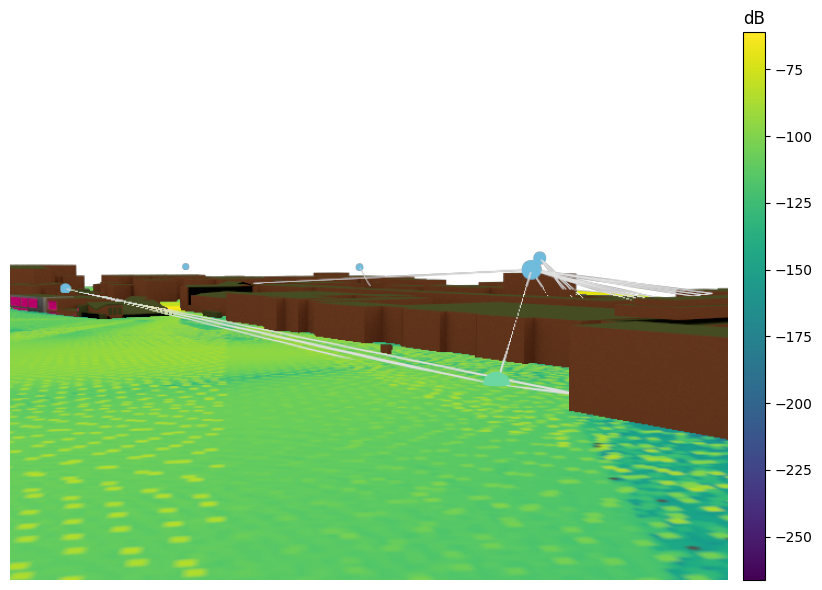

In [13]:
image = scene.render("preview", paths=paths, coverage_map=cm);
#image.savefig("image_10.png")